# Predicting term deposit subscriptions from phone marketing data

The UCI Bank Marketing dataset records ~45,000 phone calls a Portuguese bank made to sell term deposits. Goal: predict from client and campaign information available **before** the call whether the client subscribes.

Two models are compared: logistic regression as a linear baseline, hist gradient boosting as the performance model.


In [74]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
DATA_PATH = Path("data/bank-full.csv")

## Data loading



In [75]:
df = pd.read_csv(DATA_PATH, sep=";")
df.shape

(45211, 17)

In [76]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [77]:
def column_overview(frame):
    return pd.DataFrame({
        "dtype": frame.dtypes.astype(str),
        "n_unique": frame.nunique(),
        "n_missing": frame.isna().sum(),
        "n_unknown": frame.eq("unknown").sum(),
    })

column_overview(df)

,dtype,n_unique,n_missing,n_unknown
age,int64,77,0,0
job,str,12,0,288
marital,str,3,0,0
education,str,4,0,1857
default,str,2,0,0
balance,int64,7168,0,0
housing,str,2,0,0
loan,str,2,0,0
contact,str,3,0,13020
day,int64,31,0,0


In [78]:
print(f"rows: {len(df)}, duplicate rows: {df.duplicated().sum()}")
print(df["y"].value_counts())

rows: 45211, duplicate rows: 0
y
no     39922
yes     5289
Name: count, dtype: int64


## Exploratory analysis

Charts share one format: one bar per client group, blue for non-subscribers, orange for subscribers, with the group's subscription rate on the bar and its size on the axis. A high rate on a small group deserves suspicion.


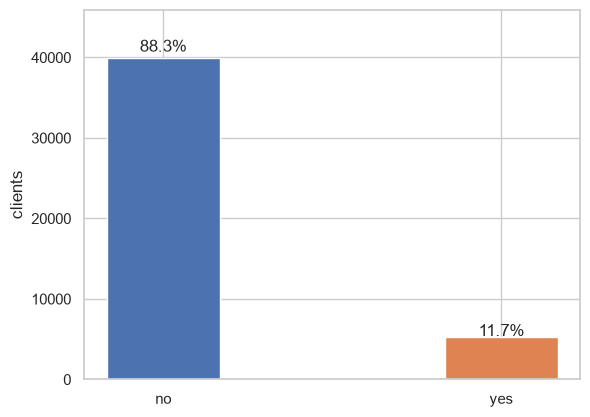

In [79]:
target_counts = df["y"].value_counts()
bar_colors = target_counts.index.map({"no": "C0", "yes": "C1"})
x = [0, 0.6]

fig, ax = plt.subplots()
ax.bar(x, target_counts.values, width=0.2, color=bar_colors)
for pos, count in zip(x, target_counts.values):
    ax.text(pos, count * 1.02, f"{count / len(df):.1%}", ha="center")
ax.set_xticks(x, target_counts.index)
ax.set_ylabel("clients")
ax.set_ylim(0, target_counts.max() * 1.15)
plt.show()

In [80]:
def yes_no_counts(groups, order=None):
    counts = df.groupby(groups, observed=False)["y"].agg(total="size", yes=lambda s: s.eq("yes").sum())
    counts["no"] = counts["total"] - counts["yes"]
    return counts.reindex(order) if order is not None else counts

def plot_yes_counts(counts, title, ax, horizontal=False):
    # yes at the bottom/left so the orange segments start at zero and stay comparable
    if horizontal:
        ax.barh(range(len(counts)), counts["yes"], color="C1", label="yes")
        ax.barh(range(len(counts)), counts["no"], left=counts["yes"], color="C0", label="no")
        ax.set_yticks(range(len(counts)), counts.index)
        ax.set_xlabel("clients")
        for pos, (_, row) in enumerate(counts.iterrows()):
            ax.annotate(f"{row['total']:,} ({row['yes']:,} yes)", (row["total"], pos), textcoords="offset points", xytext=(2, 0), va="center", fontsize=8.5)
        ax.set_xlim(0, counts["total"].max() * 1.22)
    else:
        ax.bar(range(len(counts)), counts["yes"], color="C1", label="yes")
        ax.bar(range(len(counts)), counts["no"], bottom=counts["yes"], color="C0", label="no")
        ax.set_xticks(range(len(counts)), counts.index)
        ax.set_ylabel("clients")
        for pos, (_, row) in enumerate(counts.iterrows()):
            ax.annotate(f"{row['total']:,}", (pos, row["total"]), textcoords="offset points", xytext=(0, 2), ha="center", fontsize=9)
            ax.annotate(f"{row['yes']:,} yes", (pos, row["yes"]), textcoords="offset points", xytext=(0, 2), ha="center", fontsize=8, color="C1", bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
        ax.set_ylim(0, counts["total"].max() * 1.14)
    ax.set_title(title)

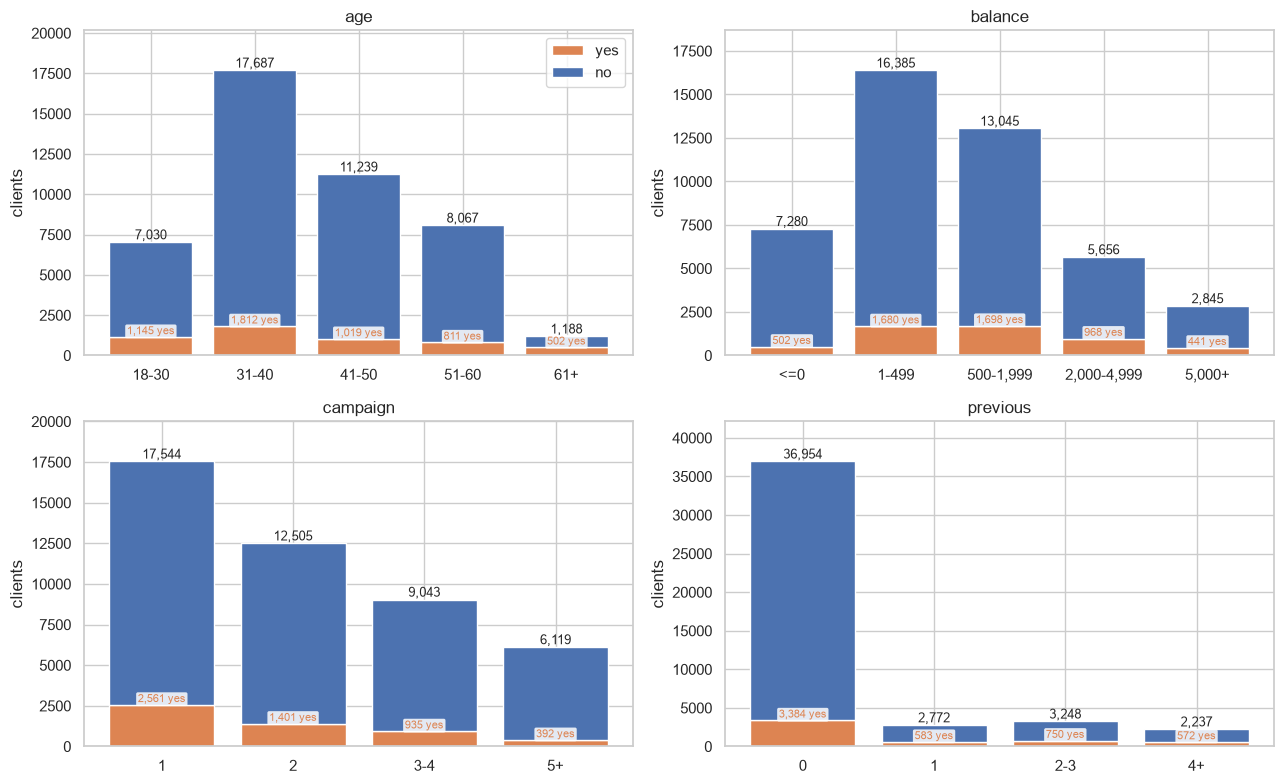

In [81]:
# bin edges chosen so every group holds a useful number of clients
NUMERIC_BINS = {
    "age": ([17, 30, 40, 50, 60, 95], ["18-30", "31-40", "41-50", "51-60", "61+"]),
    "balance": ([-10_000, 0, 500, 2_000, 5_000, 110_000], ["<=0", "1-499", "500-1,999", "2,000-4,999", "5,000+"]),
    "campaign": ([0, 1, 2, 4, 64], ["1", "2", "3-4", "5+"]),
    "previous": ([-1, 0, 1, 3, 276], ["0", "1", "2-3", "4+"]),
}

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (col, (bins, labels)) in zip(axes.flat, NUMERIC_BINS.items()):
    plot_yes_counts(yes_no_counts(pd.cut(df[col], bins=bins, labels=labels)), col, ax)
axes[0, 0].legend(loc="upper right")
plt.tight_layout()
plt.show()

- Age: U-shaped, 16.3% for the under-30s, ~10% through the working ages, 42.3% for the small 61+ group (n=1,188), mostly retirees.
- Balance: 6.9% for overdrawn clients, ~17% above 2,000. Real but modest.
- Campaign: every extra call hurts, 14.6% for a single contact down to 6.4% at five or more. The strongest numeric pattern in the data.
- Previous: clients contacted in an earlier campaign subscribe two to three times as often as first-time contacts (21-26% vs 9.2%). Half of all clients get one or two calls, and 81.7% were never contacted before.
- pdays: overlaps with `previous` (both encode "was contacted before", see the correlation below), so it gets no chart here, only a flag in preprocessing.


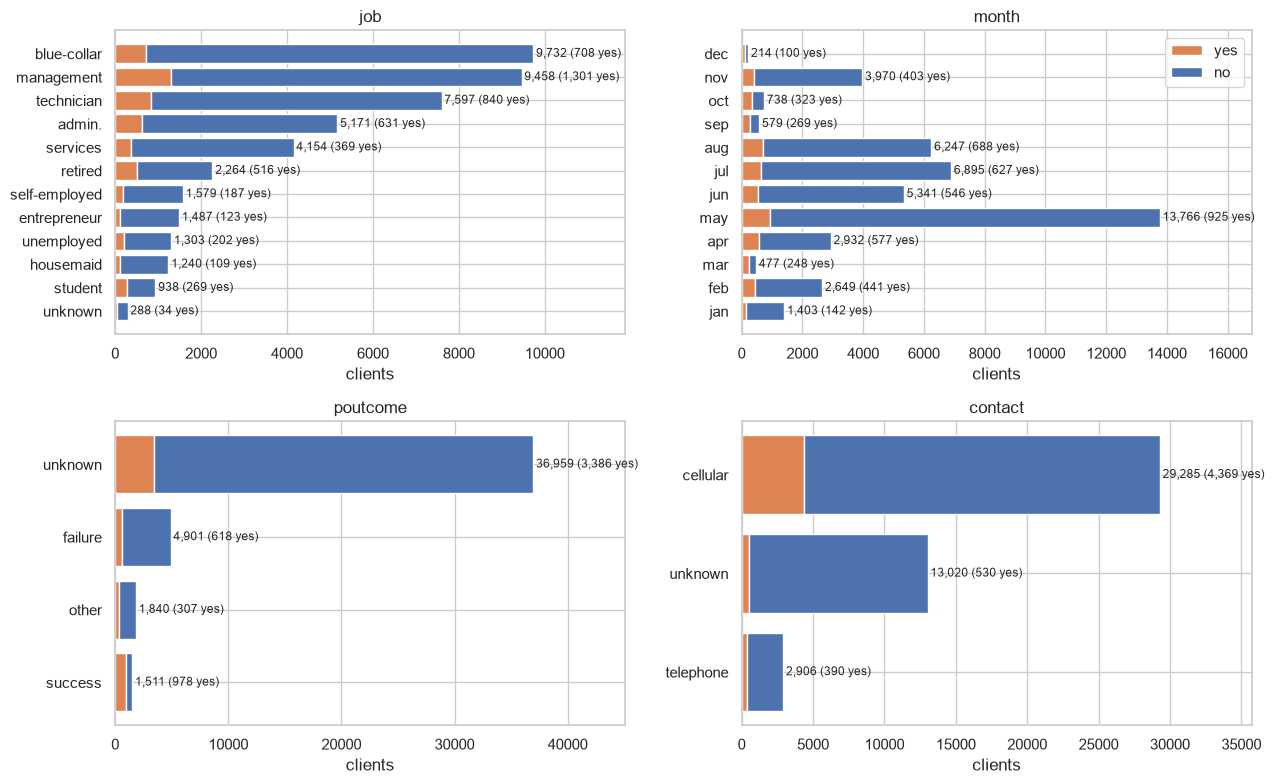

In [82]:
# months in calendar order, the rest sorted by group size
MONTH_ORDER = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
panels = [("job", None), ("month", MONTH_ORDER), ("poutcome", None),
          ("contact", None)]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (col, order) in zip(axes.flat, panels):
    counts = yes_no_counts(df[col], order=order)
    if order is None:
        counts = counts.sort_values("total")
    plot_yes_counts(counts, col, ax, horizontal=True)
axes[0, 1].legend(loc="upper right")
plt.tight_layout()
plt.show()

- Job: students (28.7%) and retirees (22.8%) subscribe far above the 11.7% base rate, blue-collar workers (7.3%) far below.
- poutcome: a client whose previous campaign ended in a success subscribes again at ~64%, the strongest feature in the dataset.
- Contact: unknown contact type subscribes at 4.1% vs 14.9% for cellular, so how a client was reached matters as much as who they are.
- Month: March, September, October and December run at 44-52% vs 6.7% in May, but May to August carries 71% of all calls. Part of the month effect is likely which clients are called then, not the month itself.


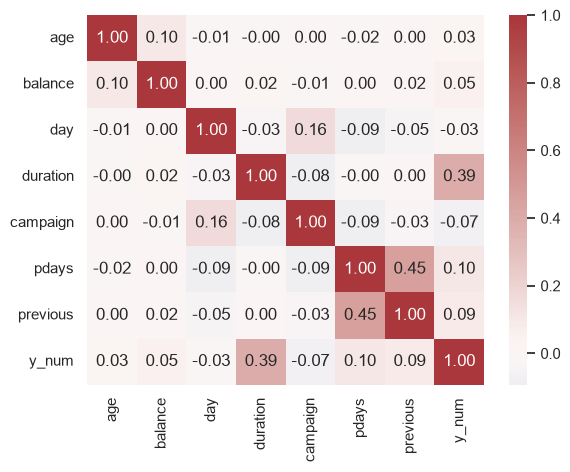

In [83]:
corr = df[["age", "balance", "day", "duration", "campaign", "pdays", "previous"]].assign(
    y_num=df["y"].eq("yes").astype(int)
).corr()

plt.figure()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0)
plt.show()

`duration` correlates with the target at 0.40, far above everything else: people who subscribe are the people who stayed on the phone. It is only known after the call, so it cannot be used at prediction time.

Among the usable features correlations are weak. `pdays` and `previous` correlate at 0.46 because both encode "was contacted before".


## Metric choice

Who should the call center phone next? With 11.7% positives, a rule that calls no one already scores 88.3% accuracy while catching nobody, so accuracy is out and a ranking metric is needed.


ROC-AUC hides the imbalance: random guessing already scores 0.5 no matter how skewed the classes are.

PR-AUC makes it visible: random guessing traces a flat line at 11.7% precision, so its area is 0.117, and a good model pushes that area up. Precision at a given recall reads directly as wasted calls vs subscribers caught. PR-AUC is primary; F1 joins the table as a compact balance at the default cutoff.

The operating point depends on the call budget, a management decision, so the evaluation section tunes a threshold on a validation split and shows the top-N% menu next to it.

`previous` goes with it: subscription rates sit at 21-26% whether a client had 1, 2-3 or 4+ prior contacts, so the contacted-before flag plus `poutcome` carry its signal.


In [84]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    make_scorer,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# -1 in pdays always pairs with previous = 0, one flag covers both
X = df.drop(columns=["y", "duration"]).assign(
    contacted_before=df["pdays"].ne(-1)
).drop(columns=["pdays", "previous"])
y = df["y"].eq("yes")

# 60/20/20: validation exists only to tune the threshold, test is scored once at the end
X_train, X_rest, y_train, y_rest = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test = train_test_split(
    X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=RANDOM_STATE
)
print(f"train: {len(X_train):,}, validation: {len(X_val):,}, test: {len(X_test):,} rows")
print(f"positive rate: train {y_train.mean():.1%}, validation {y_val.mean():.1%}, test {y_test.mean():.1%}")

train: 27,126, validation: 9,042, test: 9,043 rows
positive rate: train 11.7%, validation 11.7%, test 11.7%


Both models share one pipeline: numeric features scaled, categorical features one-hot encoded. Scaling matters only for the logistic regression, but sharing keeps the comparison honest.

Class imbalance is handled with `class_weight="balanced"`, which upweights the positives so neither model can win by predicting "no" everywhere.

Hyperparameters: small grid search on PR-AUC with 5-fold stratified CV, values chosen so the best one is not at the edge of the grid. The held-out 40% splits into a validation set for threshold tuning and a test set scored once at the end; with 45k rows giving up 20% of the training data costs little. On a small dataset I would pick the threshold cross-validated instead.


In [85]:
numeric_cols = ["age", "balance", "day", "campaign"]
categorical_cols = [c for c in X_train.columns if c not in numeric_cols]

# dense output because HistGradientBoosting does not accept sparse matrices
preprocess = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_cols),
    ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols),
])

scoring = {
    "pr_auc": make_scorer(average_precision_score, response_method="predict_proba"),
    "roc_auc": make_scorer(roc_auc_score, response_method="predict_proba"),
    "f1": make_scorer(f1_score),
    "recall": make_scorer(recall_score),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

In [86]:
lr_pipe = Pipeline([
    ("preprocess", preprocess),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000)),
])

lr_search = GridSearchCV(
    lr_pipe,
    {"model__C": [0.01, 0.03, 0.1, 1]},
    scoring=scoring,
    refit="pr_auc",
    cv=cv,
    n_jobs=-1,
)
lr_search.fit(X_train, y_train)
print(f"best PR-AUC: {lr_search.best_score_:.3f}")

best PR-AUC: 0.390


In [87]:
hgb_pipe = Pipeline([
    ("preprocess", preprocess),
    ("model", HistGradientBoostingClassifier(
        class_weight="balanced",
        max_iter=300,
        random_state=RANDOM_STATE,
    )),
])

hgb_search = GridSearchCV(
    hgb_pipe,
    {"model__learning_rate": [0.05, 0.1, 0.2], "model__max_leaf_nodes": [15, 31, 63]},
    scoring=scoring,
    refit="pr_auc",
    cv=cv,
    n_jobs=-1,
)
hgb_search.fit(X_train, y_train)
print(f"best PR-AUC: {hgb_search.best_score_:.3f}")

best PR-AUC: 0.428


In [88]:
rows = {}
for name, search in [("logistic regression", lr_search), ("hist gradient boosting", hgb_search)]:
    i = search.best_index_
    rows[name] = {m: search.cv_results_[f"mean_test_{m}"][i] for m in scoring} | {"params": search.best_params_}

pd.DataFrame(rows).T.round(3)

,pr_auc,roc_auc,f1,recall,params
logistic regression,0.390499,0.76333,0.364131,0.634419,{'model__C': 0.03}
hist gradient boosting,0.427864,0.793962,0.435577,0.624017,"{'model__learning_rate': 0.1, 'model__max_leaf..."


Both models rank far above the 0.117 random baseline. The boosting model wins on every ranking metric (PR-AUC 0.428 vs 0.390, ROC-AUC 0.794 vs 0.763). The F1 and recall columns sit at the default 0.5 cutoff, which the balanced class weights push far to the cautious side; the tuned thresholds in the next section are the operating points that matter.

The boosting model goes forward as the performance model and logistic regression stays as the reference point.


## Threshold tuning on evaluation set

A probability only becomes a call list once I pick a threshold. The default 0.5 sits way too conservative given the 88% "no" and balanced class weights, so I take the threshold that maximizes F1 on the validation set, data the models never trained on. The test set stays out of this choice.

F1 treats a wasted call and a missed subscriber as equally bad. I assume that because I have no cost data, and it is roughly fair near the top of the list. If the bank judges missed subscribers more expensive, the sweep below gives F2 or recall-floor points too, only the scoring rule changes.


In [89]:
from sklearn.metrics import precision_recall_curve, precision_score

def threshold_frame(proba, y_true):
    # precision_recall_curve appends a precision=1/recall=0 endpoint, so it is one longer than thresholds
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    scores = pd.DataFrame({"threshold": thresholds, "precision": precision[:-1], "recall": recall[:-1]})
    scores["f1"] = 2 * scores["precision"] * scores["recall"] / (scores["precision"] + scores["recall"])
    return scores

val_proba = {
    "logistic regression": lr_search.best_estimator_.predict_proba(X_val)[:, 1],
    "hist gradient boosting": hgb_search.best_estimator_.predict_proba(X_val)[:, 1],
}
val_curves = {name: threshold_frame(proba, y_val) for name, proba in val_proba.items()}
tuned_threshold = {name: scores.loc[scores["f1"].idxmax(), "threshold"] for name, scores in val_curves.items()}

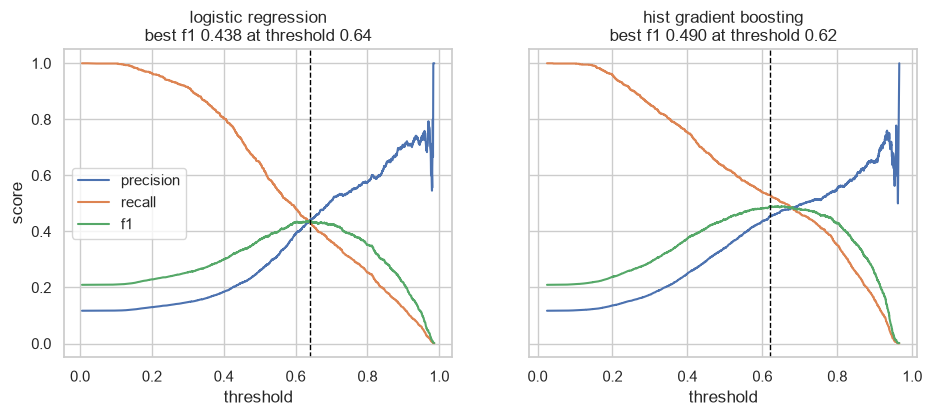

In [90]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, scores) in zip(axes, val_curves.items()):
    best = scores.loc[scores["f1"].idxmax()]
    ax.plot(scores["threshold"], scores["precision"], label="precision")
    ax.plot(scores["threshold"], scores["recall"], label="recall")
    ax.plot(scores["threshold"], scores["f1"], label="f1")
    ax.axvline(best["threshold"], color="black", lw=1, linestyle="--")
    ax.set_title(f"{name}\nbest f1 {best['f1']:.3f} at threshold {best['threshold']:.2f}")
    ax.set_xlabel("threshold")
axes[0].set_ylabel("score")
axes[0].legend()
plt.show()

In [91]:
rows = {}
for name, proba in val_proba.items():
    for label, threshold in [("default 0.5", 0.5), (f"tuned {tuned_threshold[name]:.2f}", tuned_threshold[name])]:
        pred = proba >= threshold
        rows[(name, label)] = {
            "precision": precision_score(y_val, pred),
            "recall": recall_score(y_val, pred),
            "f1": f1_score(y_val, pred),
        }

pd.DataFrame(rows).T.round(3)

precision  recall     f1
logistic regression    default 0.5      0.260   0.646  0.370
                       tuned 0.64       0.443   0.434  0.438
hist gradient boosting default 0.5      0.342   0.629  0.443
                       tuned 0.62       0.455   0.530  0.490

## Evaluation on the test set


In [92]:
from sklearn.inspection import permutation_importance

lr_proba = lr_search.best_estimator_.predict_proba(X_test)[:, 1]
hgb_proba = hgb_search.best_estimator_.predict_proba(X_test)[:, 1]

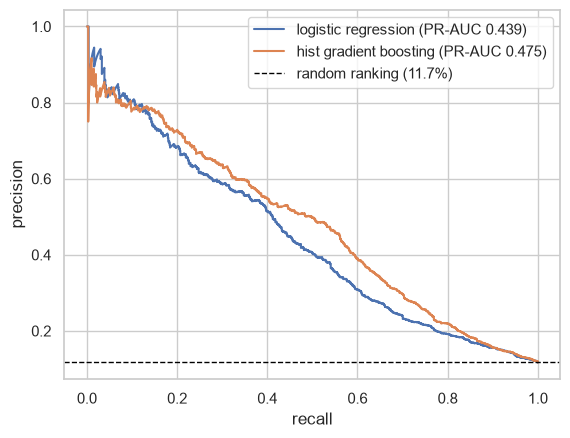

In [93]:
fig, ax = plt.subplots()
for name, proba in [("logistic regression", lr_proba), ("hist gradient boosting", hgb_proba)]:
    precision, recall, _ = precision_recall_curve(y_test, proba)
    pr_auc = average_precision_score(y_test, proba)
    ax.plot(recall, precision, label=f"{name} (PR-AUC {pr_auc:.3f})")
ax.axhline(y_test.mean(), color="black", lw=1, linestyle="--", label=f"random ranking ({y_test.mean():.1%})")
ax.set_xlabel("recall")
ax.set_ylabel("precision")
ax.legend()
plt.show()

In [94]:
def metrics_at(proba, threshold=0.5):
    pred = proba >= threshold
    return {
        "pr_auc": average_precision_score(y_test, proba),
        "roc_auc": roc_auc_score(y_test, proba),
        "f1": f1_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
    }

pd.DataFrame({
    "logistic regression": metrics_at(lr_proba, tuned_threshold["logistic regression"]),
    "hist gradient boosting": metrics_at(hgb_proba, tuned_threshold["hist gradient boosting"]),
}).T.round(3)

,pr_auc,roc_auc,f1,precision,recall
logistic regression,0.439,0.778,0.450,0.458,0.442
hist gradient boosting,0.475,0.804,0.501,0.468,0.540


At the tuned thresholds the boosting model converts 46.8% of the clients it flags and catches 54% of all test-set subscribers. The logistic regression closes much of the precision gap (45.8%) but trails on recall (0.442 vs 0.540).


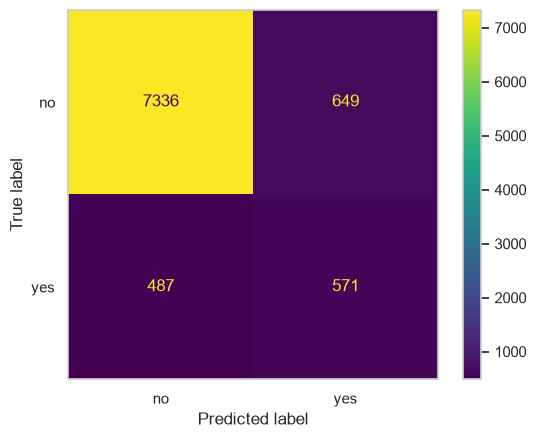

In [95]:
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay.from_predictions(
    y_test, hgb_proba >= tuned_threshold["hist gradient boosting"], display_labels=["no", "yes"], colorbar=True,
)
# whitegrid draws lines at the tick positions, cutting through the cell values
disp.ax_.grid(False)
plt.show()

Out of 1,058 test-set subscribers the model catches 571 and misses 487; the 649 false positives are wasted calls. As a call plan that is 13.5% of the calling effort for 54% of the subscribers, compared to calling everyone.


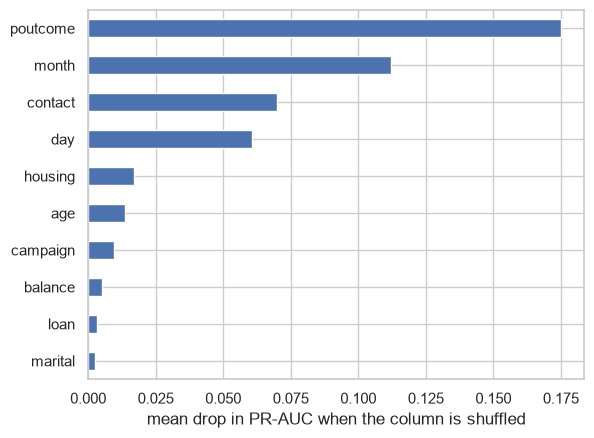

In [96]:
perm = permutation_importance(
    hgb_search.best_estimator_,
    X_test, y_test,
    scoring="average_precision",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

fig, ax = plt.subplots()
importance.tail(10).plot.barh(ax=ax)
ax.set_xlabel("mean drop in PR-AUC when the column is shuffled")
plt.show()

The ranking is driven almost entirely by campaign history: `poutcome`, `month` and `contact` dominate, and shuffling any of them costs more PR-AUC than shuffling all client demographics combined. That matches the EDA.

One caution on `month`: it reflects when the bank chose to call during this campaign, not a causal effect of calling in a given month, and may not transfer to a campaign that calls year-round.


In [97]:
ranked = pd.DataFrame({"proba": hgb_proba, "subscribed": y_test.to_numpy()}).sort_values("proba", ascending=False)

def call_stats(label, called):
    return {
        "call list": label,
        "calls": len(called),
        "precision": called["subscribed"].mean(),
        "recall": called["subscribed"].sum() / y_test.sum(),
    }

cuts = []
for cut in [0.05, 0.1, 0.2, 0.3, 0.5]:
    cuts.append(call_stats(f"top {cut:.0%}", ranked.head(int(cut * len(ranked)))))

# the tuned threshold is the operating point picked in the previous section, so it joins the menu
tuned = tuned_threshold["hist gradient boosting"]
flagged = ranked[ranked["proba"] >= tuned]
cuts.append(call_stats(f"top {len(flagged) / len(ranked):.1%} (threshold {tuned:.2f})", flagged))

pd.DataFrame(cuts).sort_values("calls").reset_index(drop=True).round(3)


,call list,calls,precision,recall
0,top 5%,452,0.650,0.278
1,top 10%,904,0.522,0.446
2,top 13.5% (threshold 0.62),1220,0.468,0.540
3,top 20%,1808,0.365,0.624
4,top 30%,2712,0.278,0.714
5,top 50%,4521,0.195,0.834


The top 13.5% row is the F1-optimal operating point from the previous section (threshold 0.62): 1,220 calls, 46.8% of them convert (4x the 11.7% base rate) and 54% of all test-set subscribers are caught. The top 20% still converts at 36.5% and catches 62%, beyond a 30% cut precision decays toward the base rate.


## Management summary

The model scores every client on how likely they are to subscribe when called, using only information available before the call, and was tested on 9,043 unseen clients.

- Recommended operating point: call the top 13.5% of the ranked list. 46.8% of those calls convert, four times the 11.7% random rate, and 54% of all would-be subscribers are reached. The top 20% catches 62.4% at 36.5% conversion.
- Strongest drivers are campaign history, not demographics: previous campaign success, low-volume months (March, September, October, December), known phone line.
- Action: score the full client base before each campaign and hand the call center the ranked list, run alongside the current selection for one campaign before rollout.
- Limits: ~46% of would-be subscribers are missed at the recommended cut, the month effect partly reflects past scheduling, and the data is from 2008 to 2010, so scores should be refreshed regularly.


## Follow-up questions

### Data worth adding

- Account transaction history: `balance` is a single snapshot and a weak signal; flows over a few months would say much more.
- Past campaign response per channel: `poutcome` summarizes one previous campaign and 81% of clients have none, so their score leans almost entirely on demographics.

### Transferring to other bank areas

Churn prediction: same setup, tabular client data and a rare positive outcome; only the audience of the ranked list changes.

### Reframing the problem

The model answers "who is likely to subscribe", but a client who would have subscribed anyway is a wasted call. With a control group that was not called, the target could be the *difference* the call makes (uplift). This dataset has no holdout group, so that model cannot be built from it.
